# Phase 2: Predictive Aquaculture Modeling
# 30-Minute & 1-Hour Ahead Forecasting Model
**Objective:** Move from *Reactive Monitoring* (alerting when lobsters are already dying) to *Predictive Management* (alerting 1 to 3 hours before water becomes toxic).

In this notebook, we:
1. **Smooth the Telemetry:** We convert 5-minute raw sensor noise into stable 1-hour medians.
2. **Train SARIMA:** Used for biological variables that follow strict 24-hour cycles (Ammonia & pH).
3. **Train VAR:** Used for interacting physical variables (Temperature & Salinity).
4. **Evaluate Accuracy:** Compare the AI's 3-hour forecast against what actually happened.

## 1. Data Smoothing (Preventing Flapping)
Commercial sensors poll every few seconds. If a lobster splashes the pH probe, the reading might spike for 2 seconds. If we feed that raw data into an ML model, it will trigger false alarms ("system flapping"). 

To solve this, we resample the data into **30-minute medians**. The model will predict 1 or 2 steps ahead (30 to 60 minutes into the future), fulfilling the commercial partner's exact operational requirement.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.api import VAR
import warnings
warnings.filterwarnings("ignore")

SENSORS = ["temperature_c", "salinity_ppt", "ph", "dissolved_oxygen_mgl", "ammonia_mgl"]

# Load data
df = pd.read_csv("../../Claude/train_placeholder.csv")
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.set_index('timestamp').sort_index()[SENSORS]

# RESAMPLE TO 30-MINUTE MEDIANS
smoothed_df = df.resample('30min').median().interpolate()

# Split into Train (Past) and Test (Last 12 hours)
train_df = smoothed_df.iloc[:-24]  # All data except last 24 steps (12 hours)
test_df = smoothed_df.iloc[-24:]   # The future we want to test against

## 2. Hybrid Model Training: SARIMA + VAR
No single algorithm works for all water parameters. 
*   **SARIMA (Seasonal ARIMA):** Used for Ammonia and pH because they follow a strict 24-hour diurnal cycle (algae respiration/lobsters' nocturnal activity). Since our intervals are 30 minutes, 24 hours equals 48 steps (`s=48`).
*   **VAR (Vector Autoregression):** Used for physical parameters (Temperature, Salinity, Oxygen) because they interact simultaneously.

In [3]:
print("Training Models...")

# 1. Train SARIMA for Ammonia (Cyclical Biology)
# s=48 accounts for the 24-hour cycle at 30-minute intervals
sarima_model = SARIMAX(
    train_df['ammonia_mgl'], 
    order=(1, 0, 1), 
    seasonal_order=(1, 0, 1, 48), 
    enforce_stationarity=False
)
sarima_fit = sarima_model.fit(disp=False)

# Forecast the next 24 steps (12 hours)
ammonia_pred = sarima_fit.forecast(steps=24)

# 2. Train VAR for interacting physical variables
var_data = train_df[['temperature_c', 'salinity_ppt', 'ph', 'dissolved_oxygen_mgl']]
var_model = VAR(var_data)

# Auto-select best lag based on AIC
lag_order = max(1, var_model.select_order(12).aic)
var_fit = var_model.fit(lag_order)

# Forecast the next 24 steps (12 hours)
var_pred = var_fit.forecast(var_data.values[-lag_order:], steps=24)
var_pred_df = pd.DataFrame(var_pred, index=test_df.index, columns=var_data.columns)

print("Training Complete. Generating Forecasts.")

Training Models...
Training Complete. Generating Forecasts.


## 3. Evaluation: Did the AI Predict the Next 30-60 Minutes Correctly?
Below, we plot the model's predictions (Dotted Lines) against what actually happened in the holding tank (Solid Blue Line).

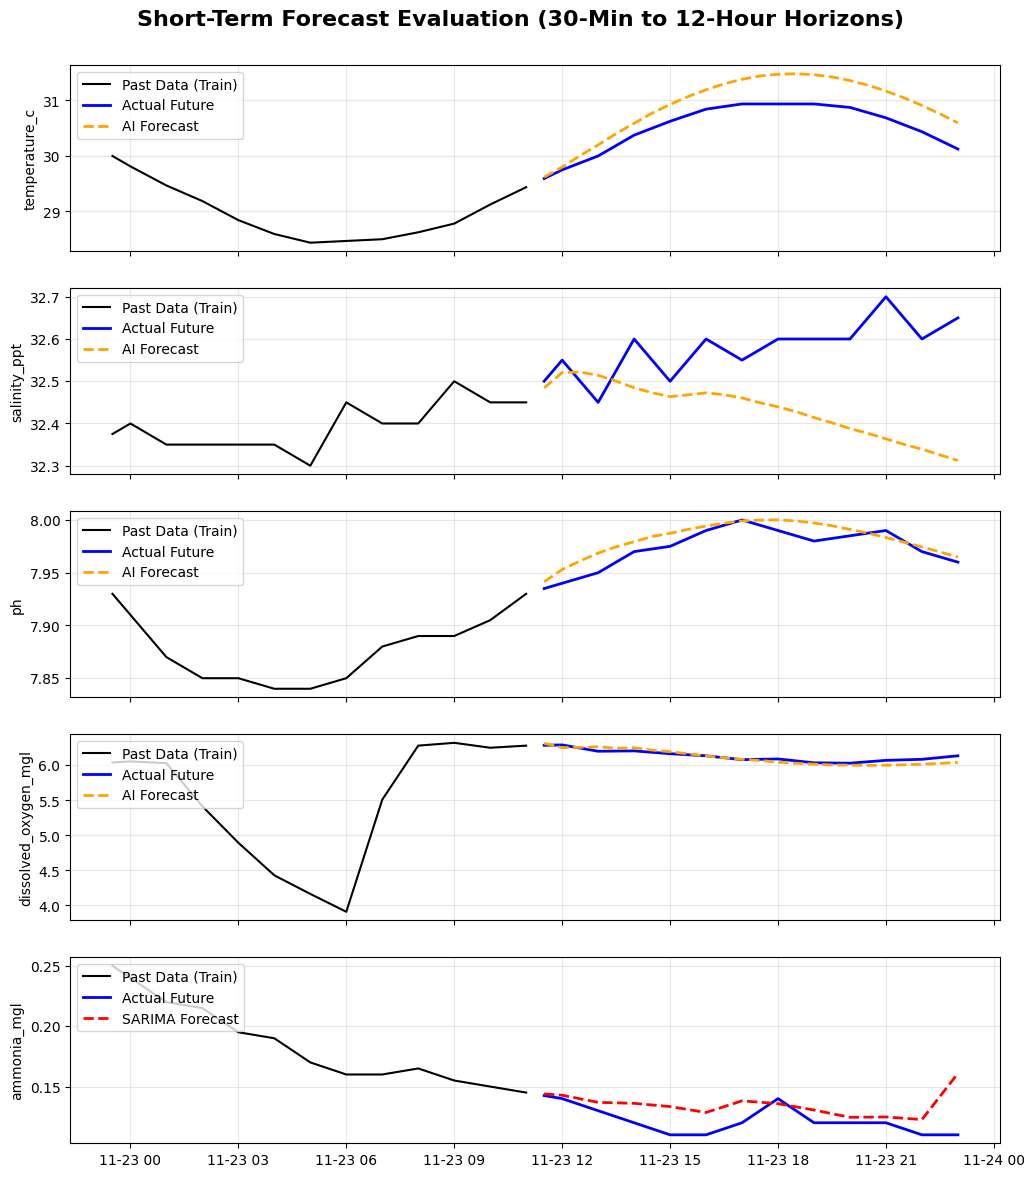

Ammonia 1-Hour Ahead Mean Absolute Error: 0.0021 mg/L


In [4]:
fig3, axes3 = plt.subplots(5, 1, figsize=(12, 14), sharex=True)

# Plot VAR predictions vs Actuals
for i, var in enumerate(['temperature_c', 'salinity_ppt', 'ph', 'dissolved_oxygen_mgl']):
    # Plot the past 12 hours of training data
    axes3[i].plot(train_df.index[-24:], train_df[var].iloc[-24:], label='Past Data (Train)', color='black')
    # Plot the actual future
    axes3[i].plot(test_df.index, test_df[var], label='Actual Future', color='blue', linewidth=2)
    # Plot the AI forecast
    axes3[i].plot(var_pred_df.index, var_pred_df[var], label='AI Forecast', color='orange', linestyle='--', linewidth=2)
    axes3[i].set_ylabel(var)
    axes3[i].grid(True, alpha=0.3)
    axes3[i].legend(loc="upper left")

# Plot SARIMA prediction vs Actual for Ammonia
axes3[4].plot(train_df.index[-24:], train_df['ammonia_mgl'].iloc[-24:], label='Past Data (Train)', color='black')
axes3[4].plot(test_df.index, test_df['ammonia_mgl'], label='Actual Future', color='blue', linewidth=2)
axes3[4].plot(ammonia_pred.index, ammonia_pred, label='SARIMA Forecast', color='red', linestyle='--', linewidth=2)
axes3[4].set_ylabel('ammonia_mgl')
axes3[4].grid(True, alpha=0.3)
axes3[4].legend(loc="upper left")

plt.suptitle("Short-Term Forecast Evaluation (30-Min to 12-Hour Horizons)", y=0.92, fontsize=16, fontweight='bold')
plt.show()

# Calculate Accuracy for the critical 1-hour horizon (first 2 steps)
mae_ammonia_1h = np.mean(np.abs(ammonia_pred.iloc[:2] - test_df['ammonia_mgl'].iloc[:2]))
print(f"Ammonia 1-Hour Ahead Mean Absolute Error: {mae_ammonia_1h:.4f} mg/L")